In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

In [2]:
df = pd.read_csv("smartcart_customers.csv")

In [3]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,172,88,88,3,8,10,4,7,0,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,2,1,6,2,1,1,2,5,0,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,111,21,42,1,8,2,10,4,0,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,10,3,5,2,2,0,4,6,0,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,46,27,15,5,5,3,6,5,0,0


In [4]:
df.shape

(2240, 22)

In [5]:
df.isnull().sum()

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
Complain                0
Response                0
dtype: int64

# Data Preprocessing

In [6]:
# Handle Missing Values
df["Income"] = df["Income"].fillna(df["Income"].median())

In [7]:
df.isnull().sum()

ID                     0
Year_Birth             0
Education              0
Marital_Status         0
Income                 0
Kidhome                0
Teenhome               0
Dt_Customer            0
Recency                0
MntWines               0
MntFruits              0
MntMeatProducts        0
MntFishProducts        0
MntSweetProducts       0
MntGoldProds           0
NumDealsPurchases      0
NumWebPurchases        0
NumCatalogPurchases    0
NumStorePurchases      0
NumWebVisitsMonth      0
Complain               0
Response               0
dtype: int64

# Feature Eng

In [8]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'Complain', 'Response'],
      dtype='object')

In [9]:
df['age'] = 2026 - df['Year_Birth']
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,age
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,88,88,3,8,10,4,7,0,1,69
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,1,6,2,1,1,2,5,0,0,72
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,21,42,1,8,2,10,4,0,0,61
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,3,5,2,2,0,4,6,0,0,42
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,27,15,5,5,3,6,5,0,0,45


In [10]:
df['Dt_Customer'] = pd.to_datetime(df['Dt_Customer'], dayfirst='True')

ref_date = df['Dt_Customer'].max()

df['Custome_Tenure_Days'] = (ref_date-df['Dt_Customer']).dt.days

df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,age,Custome_Tenure_Days
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,88,3,8,10,4,7,0,1,69,663
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,6,2,1,1,2,5,0,0,72,113
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,42,1,8,2,10,4,0,0,61,312
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,5,2,2,0,4,6,0,0,42,139
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,15,5,5,3,6,5,0,0,45,161


In [11]:
#spending
df["total_spending"]= df['MntWines']+df['MntFruits']+df['MntMeatProducts']+df['MntFishProducts']+df['MntSweetProducts']+df['MntGoldProds']
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,age,Custome_Tenure_Days,total_spending
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,3,8,10,4,7,0,1,69,663,1617
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,2,1,1,2,5,0,0,72,113,27
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,1,8,2,10,4,0,0,61,312,776
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,2,2,0,4,6,0,0,42,139,53
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,5,5,3,6,5,0,0,45,161,422


In [12]:
#kids
df["total_children"]= df['Kidhome']+df['Teenhome']
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,age,Custome_Tenure_Days,total_spending,total_children
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,8,10,4,7,0,1,69,663,1617,0
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,1,1,2,5,0,0,72,113,27,2
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,8,2,10,4,0,0,61,312,776,0
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,2,0,4,6,0,0,42,139,53,1
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,5,3,6,5,0,0,45,161,422,1


In [13]:
#Education
df['Education'].value_counts()

Education
Graduation    1127
PhD            486
Master         370
2n Cycle       203
Basic           54
Name: count, dtype: int64

In [14]:
df['Education'] = df['Education'].replace({
    'Graduation':"Graduate", 
    'PhD' : "PostGraduate", 'Master':"PostGraduate", 
    '2n Cycle' : "UnderGraduate", 'Basic' : "UnderGraduate"
})
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,age,Custome_Tenure_Days,total_spending,total_children
0,5524,1957,Graduate,Single,58138.0,0,0,2012-09-04,58,635,...,8,10,4,7,0,1,69,663,1617,0
1,2174,1954,Graduate,Single,46344.0,1,1,2014-03-08,38,11,...,1,1,2,5,0,0,72,113,27,2
2,4141,1965,Graduate,Together,71613.0,0,0,2013-08-21,26,426,...,8,2,10,4,0,0,61,312,776,0
3,6182,1984,Graduate,Together,26646.0,1,0,2014-02-10,26,11,...,2,0,4,6,0,0,42,139,53,1
4,5324,1981,PostGraduate,Married,58293.0,1,0,2014-01-19,94,173,...,5,3,6,5,0,0,45,161,422,1


In [15]:
# Marital_Staus
df['Marital_Status'].value_counts()

Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64

In [16]:
df['Marital_Status'] = df['Marital_Status'].replace({
    'Married':"Partner", 'Together':"Partner",
    'Single' : "ALone", 'Divorced':"ALone", 'Widow' : "ALone", 'Absurd' : "ALone", "YOLO":"ALone"
})
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,age,Custome_Tenure_Days,total_spending,total_children
0,5524,1957,Graduate,ALone,58138.0,0,0,2012-09-04,58,635,...,8,10,4,7,0,1,69,663,1617,0
1,2174,1954,Graduate,ALone,46344.0,1,1,2014-03-08,38,11,...,1,1,2,5,0,0,72,113,27,2
2,4141,1965,Graduate,Partner,71613.0,0,0,2013-08-21,26,426,...,8,2,10,4,0,0,61,312,776,0
3,6182,1984,Graduate,Partner,26646.0,1,0,2014-02-10,26,11,...,2,0,4,6,0,0,42,139,53,1
4,5324,1981,PostGraduate,Partner,58293.0,1,0,2014-01-19,94,173,...,5,3,6,5,0,0,45,161,422,1


# Data Cleaning

In [17]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,age,Custome_Tenure_Days,total_spending,total_children
0,5524,1957,Graduate,ALone,58138.0,0,0,2012-09-04,58,635,...,8,10,4,7,0,1,69,663,1617,0
1,2174,1954,Graduate,ALone,46344.0,1,1,2014-03-08,38,11,...,1,1,2,5,0,0,72,113,27,2
2,4141,1965,Graduate,Partner,71613.0,0,0,2013-08-21,26,426,...,8,2,10,4,0,0,61,312,776,0
3,6182,1984,Graduate,Partner,26646.0,1,0,2014-02-10,26,11,...,2,0,4,6,0,0,42,139,53,1
4,5324,1981,PostGraduate,Partner,58293.0,1,0,2014-01-19,94,173,...,5,3,6,5,0,0,45,161,422,1


In [18]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'Complain', 'Response', 'age', 'Custome_Tenure_Days', 'total_spending',
       'total_children'],
      dtype='object')

In [19]:
cols = ['ID', 'Year_Birth', 'Kidhome','Teenhome', 'Dt_Customer', 'MntWines', 'MntFruits','MntMeatProducts', 'MntFishProducts', 'MntSweetProducts','MntGoldProds']
df_cleaned = df.drop(cols, axis=1)

In [20]:
df_cleaned.head()

,Education,Marital_Status,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,age,Custome_Tenure_Days,total_spending,total_children
0,Graduate,ALone,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0
1,Graduate,ALone,46344.0,38,2,1,1,2,5,0,0,72,113,27,2
2,Graduate,Partner,71613.0,26,1,8,2,10,4,0,0,61,312,776,0
3,Graduate,Partner,26646.0,26,2,2,0,4,6,0,0,42,139,53,1
4,PostGraduate,Partner,58293.0,94,5,5,3,6,5,0,0,45,161,422,1


In [21]:
df_cleaned.shape

(2240, 15)

# Outliers

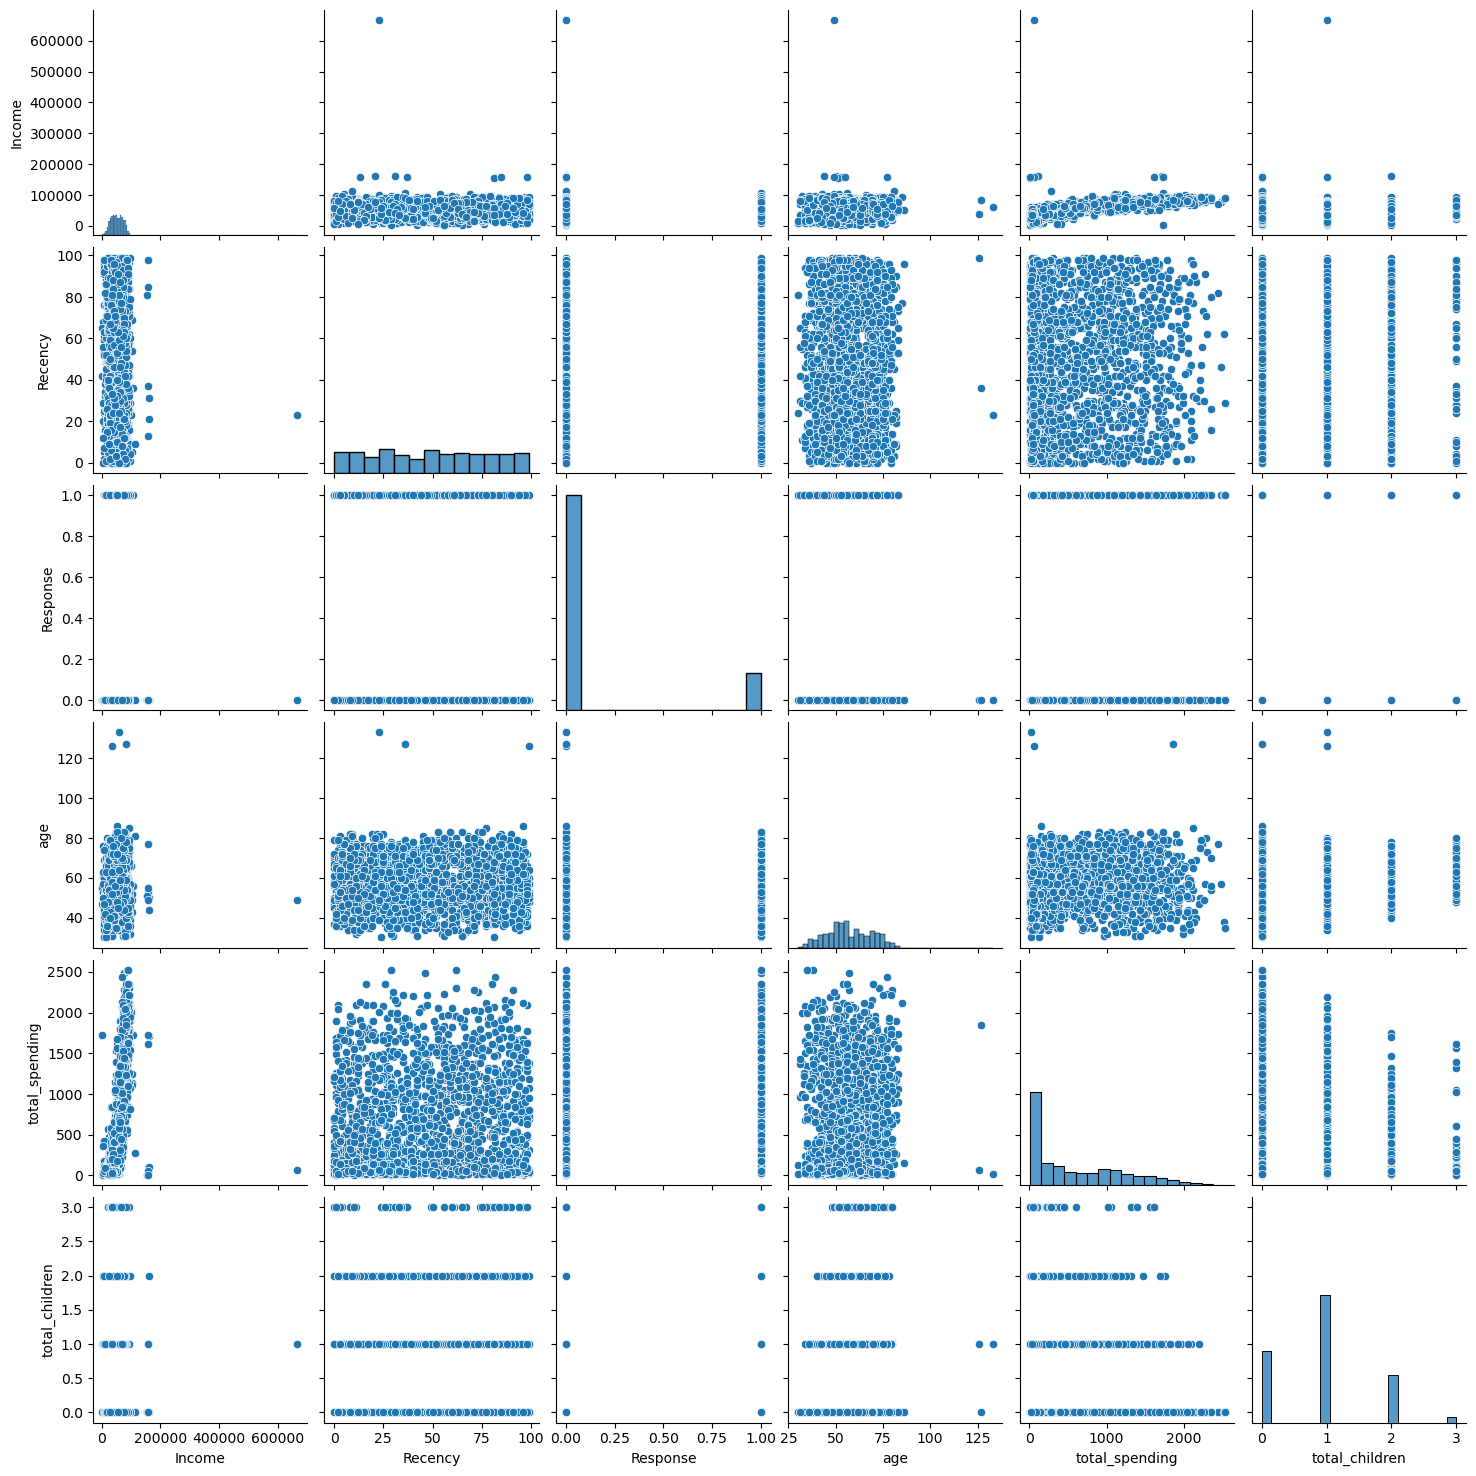

In [22]:
cols = ['Income', 'Recency', 'Response', 'age', 'total_spending', 'total_children']
sns.pairplot(df_cleaned[cols])

In [23]:
# Remove outliers
print("data size with outliers", len(df_cleaned))

df_cleaned = df_cleaned[ (df_cleaned['age'] < 90)]
df_cleaned = df_cleaned[ (df_cleaned['Income'] < 600000)]

print("data size without outliers", len(df_cleaned))

data size with outliers 2240
data size without outliers 2236


# Heatmap

In [24]:
corr_mat = df_cleaned.corr(numeric_only=True)

print(corr_mat.dtypes)

Income                 float64
Recency                float64
NumDealsPurchases      float64
NumWebPurchases        float64
NumCatalogPurchases    float64
NumStorePurchases      float64
NumWebVisitsMonth      float64
Complain               float64
Response               float64
age                    float64
Custome_Tenure_Days    float64
total_spending         float64
total_children         float64
dtype: object


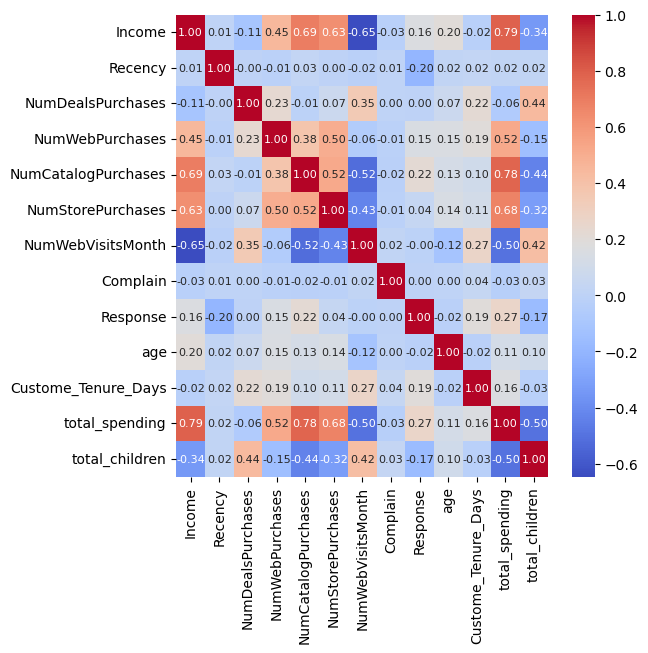

In [25]:
plt.figure(figsize=(6, 6))

sns.heatmap(
    corr_mat,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 8},
    cmap="coolwarm"
)

plt.show()

# Encoding

In [26]:
from sklearn.preprocessing import OneHotEncoder

In [27]:
ohe = OneHotEncoder()
cat_cols = ["Education", "Marital_Status"]
enc_cols = ohe.fit_transform(df_cleaned[cat_cols])

In [28]:
enc_df = pd.DataFrame(enc_cols.toarray(), columns=ohe.get_feature_names_out(cat_cols), index=df_cleaned.index)

In [29]:
df_encoded = pd.concat([df_cleaned.drop(columns=cat_cols), enc_df], axis=1)

# Preprocessing

In [30]:
from sklearn.preprocessing import StandardScaler

In [31]:
X = df_encoded
scaler = StandardScaler()

In [32]:
X_scaled = scaler.fit_transform(X)

In [33]:
X_scaled

array([[ 0.28894655,  0.30685572,  0.34873831, ...,  1.35159222,
        -0.03665357, -1.3476353 ],
       [-0.262003  , -0.38397129, -0.16869955, ...,  1.35159222,
        -0.03665357, -1.3476353 ],
       [ 0.91842301, -0.7984675 , -0.68613742, ..., -0.73986813,
        -0.03665357,  0.74204052],
       ...,
       [ 0.234898  ,  1.44672029, -0.68613742, ...,  1.35159222,
        -0.03665357, -1.3476353 ],
       [ 0.80780332, -1.42021181, -0.16869955, ..., -0.73986813,
        -0.03665357,  0.74204052],
       [ 0.04280841, -0.31488859,  0.34873831, ..., -0.73986813,
        -0.03665357,  0.74204052]])

# Visualize

In [34]:
X_scaled.shape

(2236, 19)

In [35]:
#2D
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

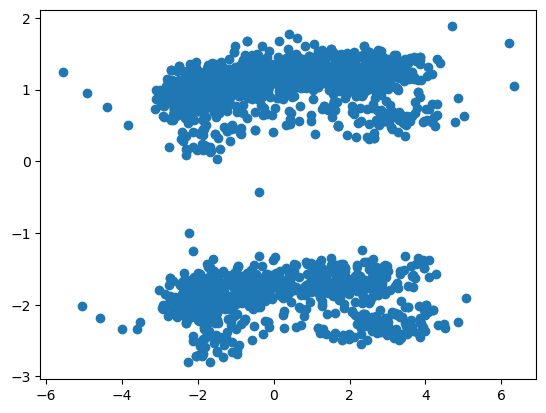

In [36]:
plt.scatter(X_pca[:, 0], X_pca[:, 1])

In [37]:
pca.explained_variance_ratio_

array([0.21948072, 0.10772484])

In [38]:
pca = PCA(n_components=3)
X_pca = pca.fit_transform(X_scaled)

In [39]:
pca.explained_variance_ratio_

array([0.21948072, 0.10772484, 0.09865717])

Text(0.5, 0.92, 'PCA')

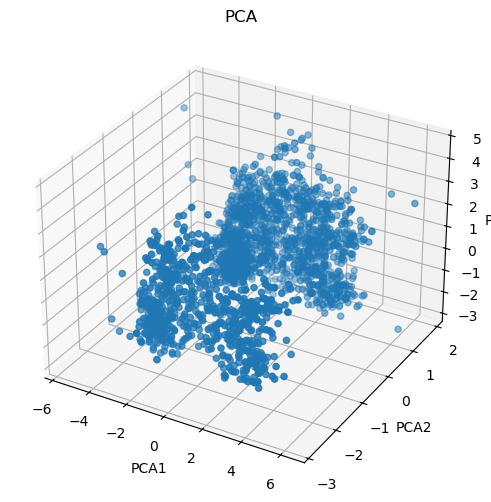

In [40]:
#plot
fig = plt.figure(figsize=(8,6))

ax = fig.add_subplot(111, projection="3d")

ax.scatter(X_pca[:, 0], X_pca[:, 1], X_pca[:, 2])

ax.set_xlabel("PCA1")
ax.set_ylabel("PCA2")
ax.set_zlabel("PCA3")
ax.set_title("PCA")

# Analyze K value

## Elbow Method

In [41]:
#import sys
#print(sys.version)

In [42]:
#!conda install -c conda-forge kneed -y

In [43]:
#!pip install kneed

In [44]:
#import sys
#print(sys.executable)

In [45]:
#!{sys.executable} -m pip show kneed

In [46]:
#import sys
#!{sys.executable} -m pip install kneed

In [41]:
from sklearn.cluster import KMeans
from kneed import KneeLocator

In [42]:
wcss = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    kmeans.fit_predict(X_pca)
    wcss.append(kmeans.inertia_)

In [43]:
knee = KneeLocator(range(1, 11), wcss, curve="convex", direction="decreasing")
optimal_k = knee.elbow

In [44]:
print("best k = ", optimal_k)

best k =  4


Text(0, 0.5, 'WCSS')

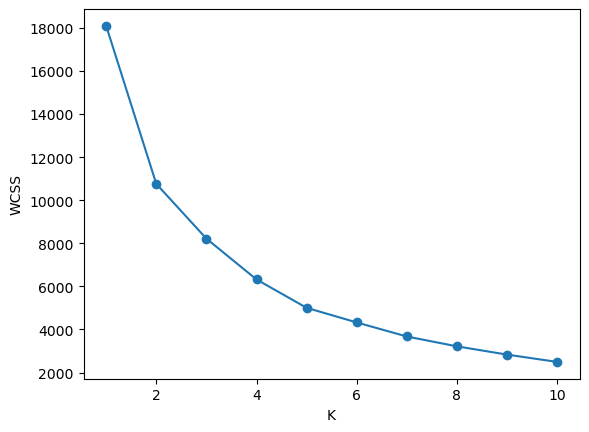

In [45]:
#plot
plt.plot(range(1, 11), wcss, marker="o")
plt.xlabel("K")
plt.ylabel("WCSS")

## Silhouette Score

Text(0, 0.5, 'Silhouette Score')

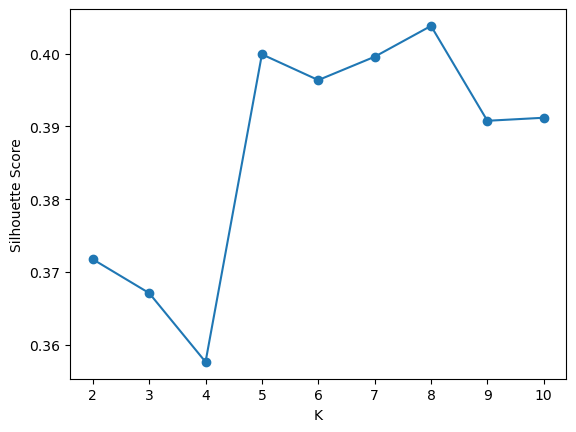

In [46]:
from sklearn.metrics import silhouette_score

scores = []
for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(X_pca)
    score = silhouette_score(X_pca, labels)
    scores.append(score)

plt.plot(range(2, 11), scores, marker="o")
plt.xlabel("K")
plt.ylabel("Silhouette Score")

Text(0, 0.5, 'Score')

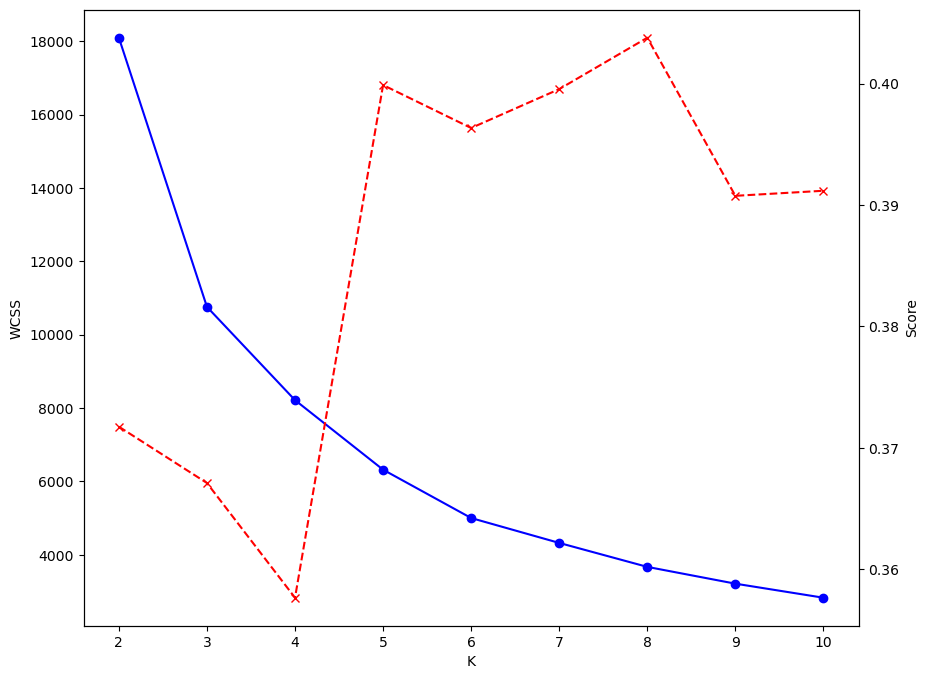

In [47]:
# Combined plot

k_range = range(2, 11)

fig, ax1 = plt.subplots(figsize=(10, 8))

ax1.plot(k_range, wcss[:len(k_range)], marker='o', color='blue')
ax1.set_xlabel("K")
ax1.set_ylabel("WCSS")

ax2 = ax1.twinx()
ax2.plot(k_range, scores[:len(k_range)], marker='x', color='red', linestyle='--')
ax2.set_ylabel("Score")

# Clustering

In [48]:
# KMeans
kmeans = KMeans(n_clusters=optimal_k, random_state=42)
labels_kmeans = kmeans.fit_predict(X_pca)

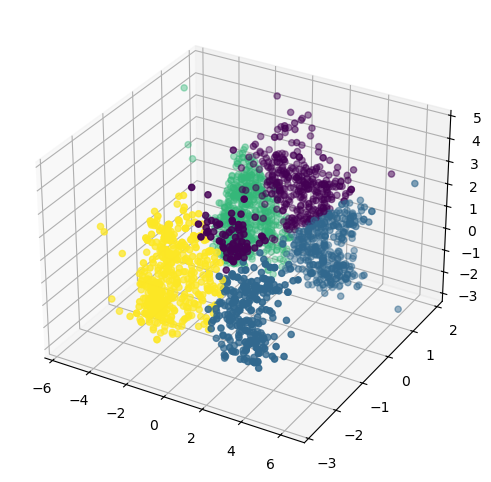

In [49]:
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(X_pca[:,0], X_pca[:,1], X_pca[:,2], c=labels_kmeans)

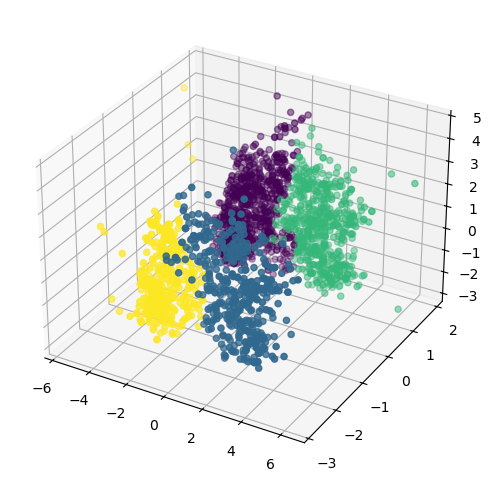

In [50]:
# Agglomerative clustering
from sklearn.cluster import AgglomerativeClustering

agg_clf = AgglomerativeClustering(n_clusters=4, linkage="ward")
labels_agg = agg_clf.fit_predict(X_pca)

fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(X_pca[:,0], X_pca[:,1], X_pca[:,2], c=labels_agg)

# Characterization of Clusters

In [51]:
X["clusters"] = labels_agg
X.head()

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,age,Custome_Tenure_Days,total_spending,total_children,Education_Graduate,Education_PostGraduate,Education_UnderGraduate,Marital_Status_ALone,Marital_Status_Alone,Marital_Status_Partner,clusters
0,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,1.0,0.0,0.0,1.0,0.0,0.0,1
1,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,1.0,0.0,0.0,1.0,0.0,0.0,3
2,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,1.0,0.0,0.0,0.0,0.0,1.0,2
3,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,1.0,0.0,0.0,0.0,0.0,1.0,0
4,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,0.0,1.0,0.0,0.0,0.0,1.0,0


<Axes: xlabel='clusters', ylabel='count'>

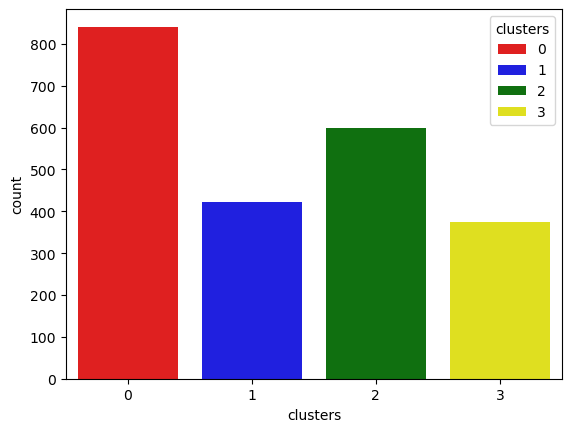

In [52]:
pal = ['red', 'blue', 'green', 'yellow']
sns.countplot(x=X["clusters"], palette=pal, hue=X["clusters"])

# Income and spending pattern

<Axes: xlabel='total_spending', ylabel='Income'>

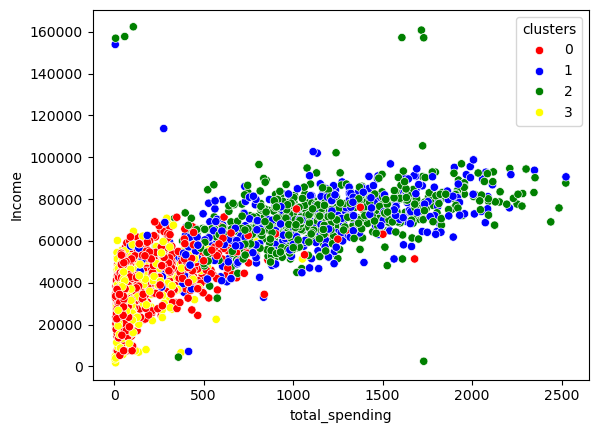

In [53]:
sns.scatterplot(x=X["total_spending"], y=X["Income"], hue=X["clusters"], palette=pal)

In [54]:
# cluster red -> low to mod spend + low to mod income
# cluster blue -> high spend + high income
# cluster green -> low spend + low income
# cluster yellow -> mod to high spend + mod income

# Cluster Summary

In [55]:
cluster_summary = X.groupby("clusters").mean()
print(cluster_summary)

                Income    Recency  NumDealsPurchases  NumWebPurchases  \
clusters                                                                
0         38257.804994  49.086801           2.569560         2.923900   
1         67279.986998  49.300236           2.245863         5.666667   
2         71263.914716  48.929766           2.061873         5.739130   
3         34534.693850  49.272727           2.291444         2.278075   

          NumCatalogPurchases  NumStorePurchases  NumWebVisitsMonth  Complain  \
clusters                                                                        
0                    0.822830           3.873960           6.428062  0.008323   
1                    4.513002           7.992908           4.184397  0.004728   
2                    5.219064           8.555184           3.702341  0.010033   
3                    0.622995           3.219251           6.692513  0.013369   

          Response        age  Custome_Tenure_Days  total_spending  \
clus